In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
from IPython.display import clear_output

# Configuración estética de las gráficas
plt.style.use('seaborn-v0_8-muted')

In [2]:
class NQueensGA:
    def __init__(self, N, pop_size=50, max_gen=1500, k_mut=4):
        self.N = N
        self.pop_size = pop_size
        self.max_gen = max_gen
        self.k_mut = k_mut
        self.chromosome_len = N * N
        self.M = N * (N - 1) / 2  # Máximo de pares (fitness ideal)
        self.population = self.init_population()

    def init_population(self):
        # Inicialización binaria aleatoria seguida de reparación
        pop = np.random.randint(2, size=(self.pop_size, self.chromosome_len))
        return np.array([self.reparar(ind) for ind in pop])

    def reparar(self, cromosoma):
        tablero = cromosoma.reshape(self.N, self.N).copy()
        
        # 1. Garantizar exactamente una reina por fila
        for i in range(self.N):
            reinas_en_fila = np.where(tablero[i] == 1)[0]
            if len(reinas_en_fila) == 0:
                tablero[i, random.randint(0, self.N - 1)] = 1
            elif len(reinas_en_fila) > 1:
                tablero[i, :] = 0
                tablero[i, random.choice(reinas_en_fila)] = 1
        
        # 2. Ajuste fino del total de reinas a N (en caso de inconsistencias)
        total = np.sum(tablero)
        while total > self.N:
            r, c = np.argwhere(tablero == 1)[random.randint(0, int(total-1))]
            tablero[r, c] = 0
            total -= 1
        while total < self.N:
            r, c = random.randint(0, self.N-1), random.randint(0, self.N-1)
            if tablero[r, c] == 0:
                tablero[r, c] = 1
                total += 1
        return tablero.flatten()

    def calcular_conflictos(self, cromosoma):
        tablero = cromosoma.reshape(self.N, self.N)
        reinas = np.argwhere(tablero == 1)
        conflictos = 0
        for i in range(len(reinas)):
            for j in range(i + 1, len(reinas)):
                ri, ci = reinas[i]
                rj, cj = reinas[j]
                # No evaluamos filas porque el reparador garantiza ri != rj
                if ci == cj or abs(ri - rj) == abs(ci - cj):
                    conflictos += 1
        return conflictos

    def fitness(self, cromosoma):
        # Maximización: M - C (donde M es el máximo de pares)
        return self.M - self.calcular_conflictos(cromosoma)

    def seleccion_ranking(self, fits):
        idx = np.argsort(fits)
        ranks = np.empty_like(idx)
        ranks[idx] = np.arange(1, self.pop_size + 1)
        prob = ranks / ranks.sum()
        sel_idx = np.random.choice(len(self.population), size=2, p=prob, replace=False)
        return self.population[sel_idx[0]], self.population[sel_idx[1]]

    def cruza_dos_puntos(self, p1, p2):
        pt1, pt2 = sorted(random.sample(range(self.chromosome_len), 2))
        h1 = np.concatenate([p1[:pt1], p2[pt1:pt2], p1[pt2:]])
        h2 = np.concatenate([p2[:pt1], p1[pt1:pt2], p2[pt2:]])
        return self.reparar(h1), self.reparar(h2)

    def mutacion_negacion(self, cromosoma):
        idx = random.sample(range(self.chromosome_len), self.k_mut)
        for i in idx:
            cromosoma[i] = 1 - cromosoma[i]
        return self.reparar(cromosoma)

    def ejecutar(self):
        best_fitness_history = []
        for gen in range(self.max_gen):
            fits = np.array([self.fitness(ind) for ind in self.population])
            mejor_idx = np.argmax(fits)
            mejor_fit = fits[mejor_idx]
            best_fitness_history.append(mejor_fit)
            
            if mejor_fit == self.M: # Solución óptima encontrada
                restante = self.max_gen - len(best_fitness_history)
                best_fitness_history.extend([self.M] * restante)
                break
            
            # Elitismo + Reemplazo
            nueva_gen = [self.population[mejor_idx].copy()]
            while len(nueva_gen) < self.pop_size:
                p1, p2 = self.seleccion_ranking(fits)
                h1, h2 = self.cruza_dos_puntos(p1, p2)
                nueva_gen.append(self.mutacion_negacion(h1))
                if len(nueva_gen) < self.pop_size:
                    nueva_gen.append(self.mutacion_negacion(h2))
            
            self.population = np.array(nueva_gen)
        return best_fitness_history

In [3]:
N_values = [4, 20, 50]
iteraciones = 35
resultados_master = {}

for n in N_values:
    print(f"Iniciando experimentos para N = {n}...")
    corridas = []
    for i in range(iteraciones):
        ga = NQueensGA(N=n)
        historial = ga.ejecutar()
        corridas.append(historial)
        if (i+1) % 5 == 0:
            print(f"  > Completadas {i+1}/{iteraciones} corridas")
    resultados_master[n] = np.array(corridas)
print("\n¡Experimentos finalizados!")

Iniciando experimentos para N = 4...
  > Completadas 5/35 corridas
  > Completadas 10/35 corridas
  > Completadas 15/35 corridas
  > Completadas 20/35 corridas
  > Completadas 25/35 corridas
  > Completadas 30/35 corridas
  > Completadas 35/35 corridas
Iniciando experimentos para N = 20...
  > Completadas 5/35 corridas
  > Completadas 10/35 corridas
  > Completadas 15/35 corridas
  > Completadas 20/35 corridas
  > Completadas 25/35 corridas
  > Completadas 30/35 corridas
  > Completadas 35/35 corridas
Iniciando experimentos para N = 50...
  > Completadas 5/35 corridas
  > Completadas 10/35 corridas
  > Completadas 15/35 corridas
  > Completadas 20/35 corridas
  > Completadas 25/35 corridas
  > Completadas 30/35 corridas
  > Completadas 35/35 corridas

¡Experimentos finalizados!


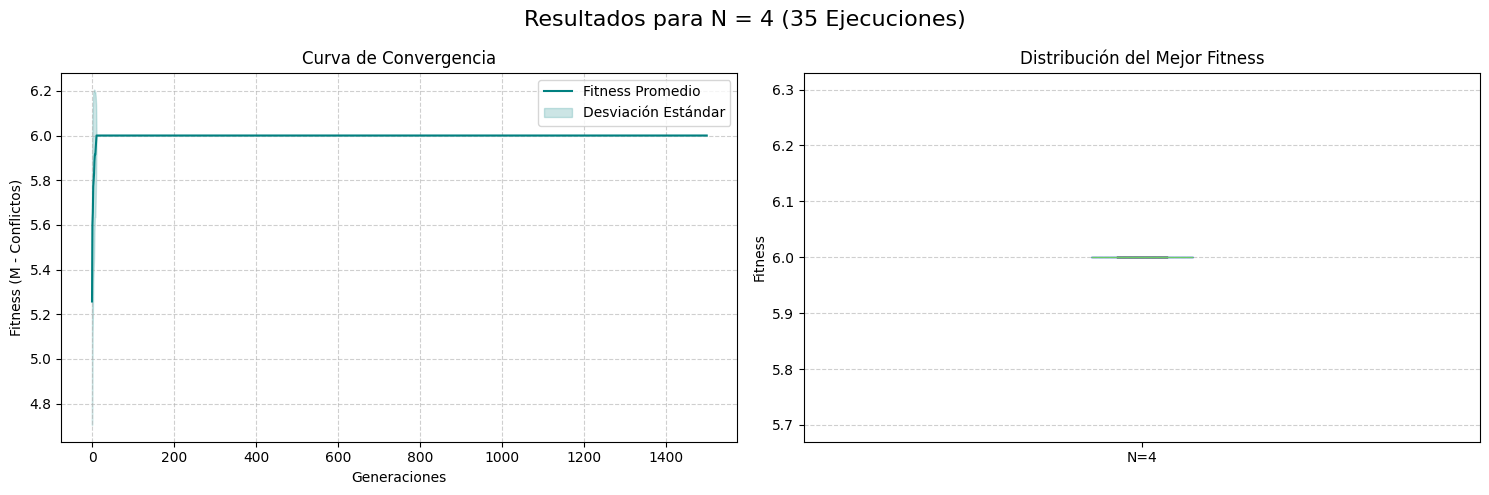

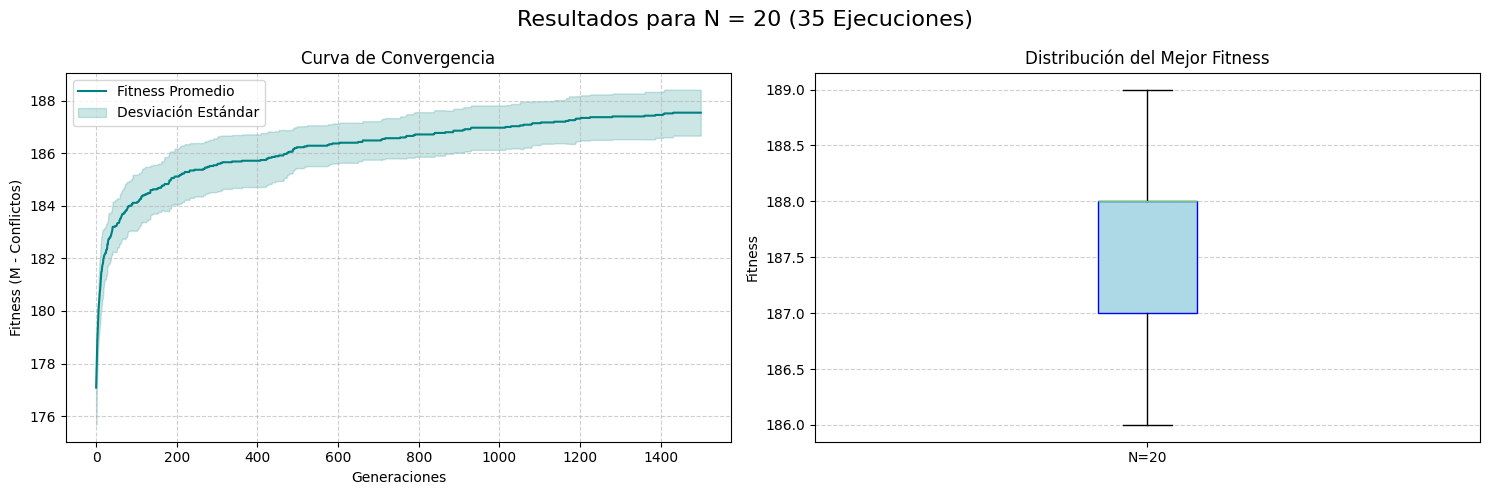

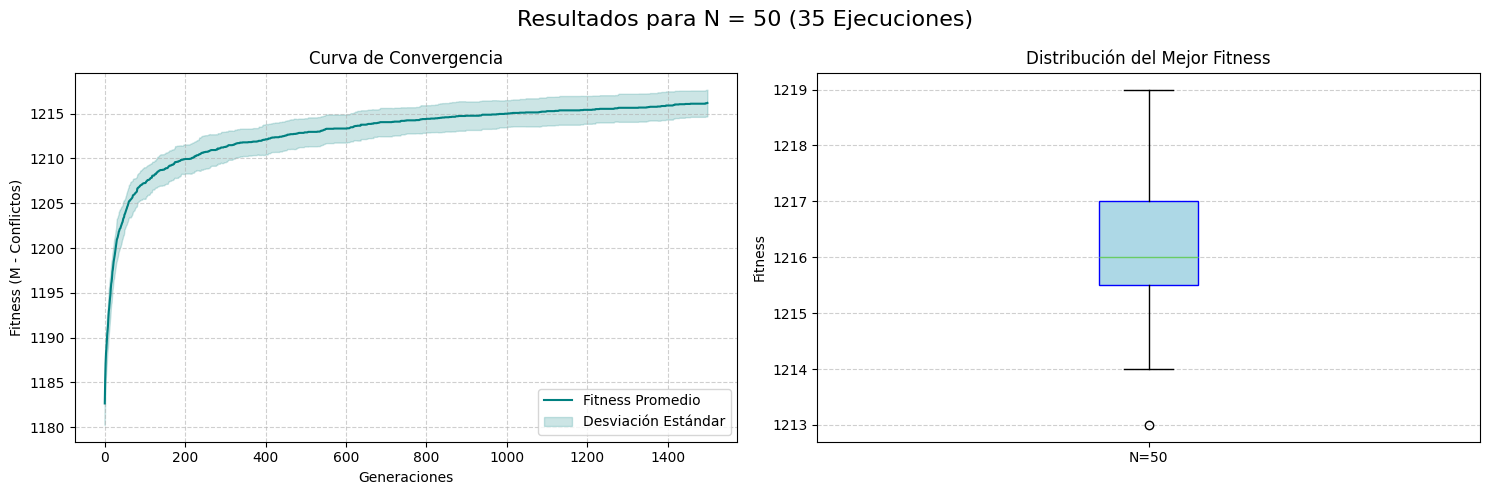

In [6]:
for n in N_values:
    data = resultados_master[n]
    mean_fitness = np.mean(data, axis=0)
    std_fitness = np.std(data, axis=0)
    # El mejor fitness de cada corrida es el último valor del historial
    mejor_fitness_final = data[:, -1]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    fig.suptitle(f"Resultados para N = {n} (35 Ejecuciones)", fontsize=16)

    # 1. Gráfica de Convergencia
    ax1.plot(mean_fitness, color='teal', label='Fitness Promedio')
    ax1.fill_between(range(len(mean_fitness)), 
                     mean_fitness - std_fitness, 
                     mean_fitness + std_fitness, 
                     color='teal', alpha=0.2, label='Desviación Estándar')
    ax1.set_title("Curva de Convergencia")
    ax1.set_xlabel("Generaciones")
    ax1.set_ylabel("Fitness (M - Conflictos)")
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.legend()

    # 2. Boxplot
    ax2.boxplot(mejor_fitness_final, patch_artist=True, 
                boxprops=dict(facecolor='lightblue', color='blue'))
    ax2.set_title("Distribución del Mejor Fitness")
    ax2.set_xticklabels([f'N={n}'])
    ax2.set_ylabel("Fitness")
    ax2.grid(axis='y', linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()